# EDA: populations, features and host composition

Once we have recomputed these fields on the TNG300 side, we assess how the marginal distributions differ between the simulations.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'pyproject.toml').is_file())
def table(relative):
    return pd.read_csv(ROOT / 'results' / relative)
def saved_json(relative):
    return json.loads((ROOT / 'results' / relative).read_text(encoding='utf-8'))
plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 16)

To ensure a fair comparison between the simulations, we recompute stellar velocity
dispersion, stellar mass fraction in metals, and κcorot. This is because either the
field does not exist in the other simulation or it is computed differently.

The particle scripts use bound stars, exclude wind particles, and match centring and
weighting as closely as possible. Stellar velocity dispersion is a global second moment
about the stellar centre-of-mass velocity; ordered rotation is not subtracted. κcorot
measures the fraction of kinetic energy in corotation. Metallicity enters as
log10(Zstar/0.0127). These comparisons do not harmonize the underlying halo finders.

The following compact histograms are aggregates of the final pair tables. Their CDFs use bin edges, so the exact KS values come from the saved
unbinned checks. Both simulations are normalized separately.


### Colour and stellar mass

![Colour–stellar-mass comparison](../results/populations/colour_stellar_mass.png)

The figure counts final pair-member entries: 285,426 for FLAMINGO and 3,060 for
TNG300. A galaxy can appear more than once. The g-r=0.68 line defines the descriptive
blue/red classes. The marked MW and M31 colours are illustrative positions, not
extra conditioning inputs for the six models.


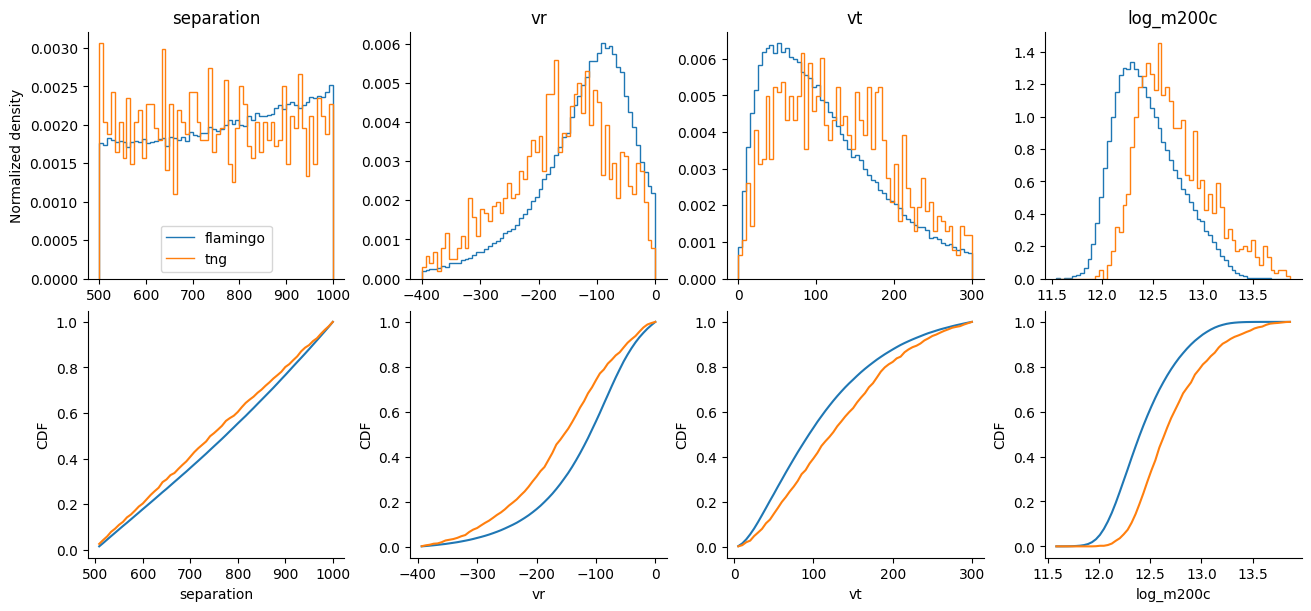

In [2]:
hist = table('populations/pair_histograms.csv')
fig, axes = plt.subplots(2,4,figsize=(13,6),layout='constrained')
for j, feature in enumerate(['separation','vr','vt','log_m200c']):
    for domain, part in hist.query('feature == @feature').groupby('domain'):
        centre = (part.lower + part.upper)/2
        axes[0,j].stairs(part['count'] / (part.n * (part.upper-part.lower)),
                         np.r_[part.lower.to_numpy(),part.upper.iloc[-1]],label=domain)
        axes[1,j].plot(part.upper, part.cdf, label=domain)
    axes[0,j].set_title(feature)
    axes[1,j].set(xlabel=feature, ylabel='CDF')
axes[0,0].set_ylabel('Normalized density'); axes[0,0].legend()
plt.show()

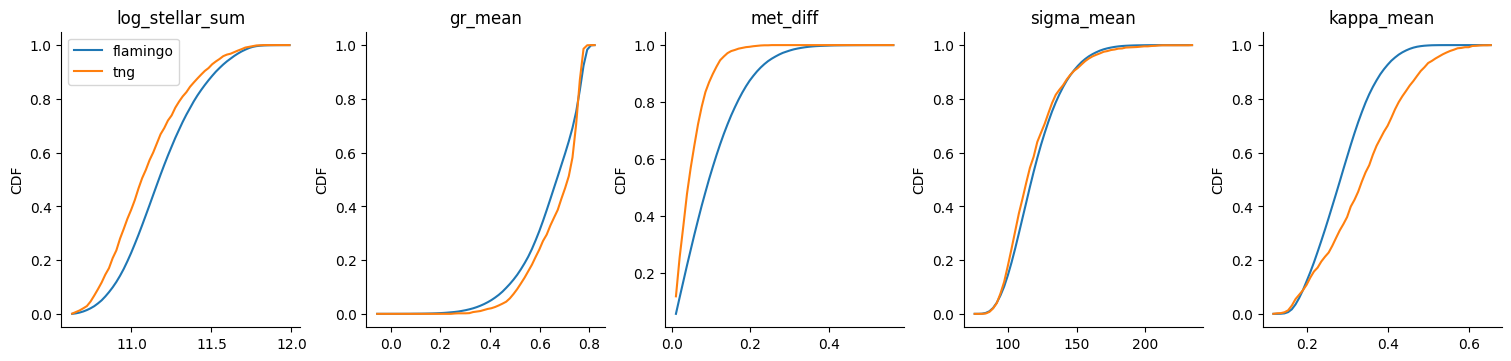

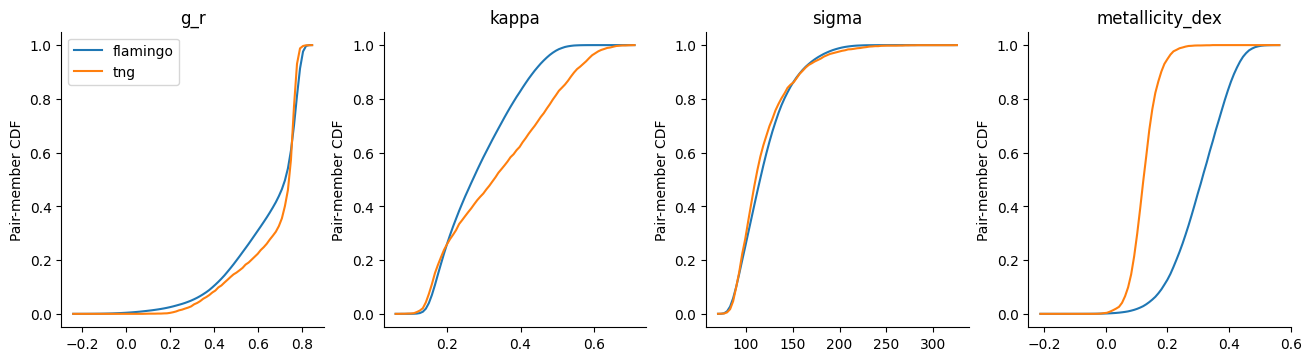

In [3]:
features = ['log_stellar_sum','gr_mean','met_diff','sigma_mean','kappa_mean','log_mass_ratio']
available = [f for f in features if f in set(hist.feature)]
fig, axes = plt.subplots(1,len(available),figsize=(15,3.5),layout='constrained')
for ax, feature in zip(axes, available):
    for domain, part in hist.query('feature == @feature').groupby('domain'):
        ax.plot(part.upper, part.cdf, label=domain)
    ax.set(title=feature, ylabel='CDF')
axes[0].legend(); plt.show()
mh = table('populations/member_feature_histograms.csv')
fig, axes = plt.subplots(1,4,figsize=(13,3.5),layout='constrained')
for ax, feature in zip(axes,['g_r','kappa','sigma','metallicity_dex']):
    for domain, part in mh.query('feature == @feature').groupby('domain'):
        ax.plot(part.upper,part.cdf,label=domain)
    ax.set(title=feature, ylabel='Pair-member CDF')
axes[0].legend(); plt.show()

### Exact feature-distribution checks

The unbinned checks below correspond to thesis Table 3.5. They use the individual
feature values rather than the plotted histogram bins. A galaxy contributes once per pair in
which it appears. The normalized Wasserstein distance divides the linear-feature W1
by the saved pooled standard-deviation normalizer.

The metallicity row uses the **linear** stellar metal mass fraction Zstar. The member
CDF above instead displays log10(Zstar/0.0127). Those are different transformations;
do not compare their Wasserstein distances as though their units were the same.
Disc fractions below use the same pair-member weighting and κcorot > 0.35.


In [4]:
audit=saved_json('populations/calculated_tables.json')
distribution_checks=pd.DataFrame(audit['distributions']).T
display(distribution_checks[['n_flamingo','n_tng','ks','wasserstein','normalizer','normalized_wasserstein']])
display(pd.Series(audit['disc_fraction_pair_member'],name='Pair-member disc fraction at kappa > 0.35').to_frame())

,n_flamingo,n_tng,ks,wasserstein,normalizer,normalized_wasserstein
sigma,285426.0,3060.0,0.081592,3.390320,27.512221,0.123230
kappa,285426.0,3060.0,0.208482,0.057043,0.102624,0.555848
color,285426.0,3060.0,0.119493,0.034489,0.170165,0.202681
metallicity,285426.0,3060.0,0.825364,0.009251,0.005275,1.753797


,Pair-member disc fraction at kappa > 0.35
flamingo,0.284624
tng,0.459477


### Population differences and host membership

The target medians differ by approximately 0.244 dex. The next figure shows that
host composition also changes with separation. Reweighting the separation distribution
alone does not remove the host-fraction difference. Equal numbers of pair rows therefore
do not imply equivalent populations.


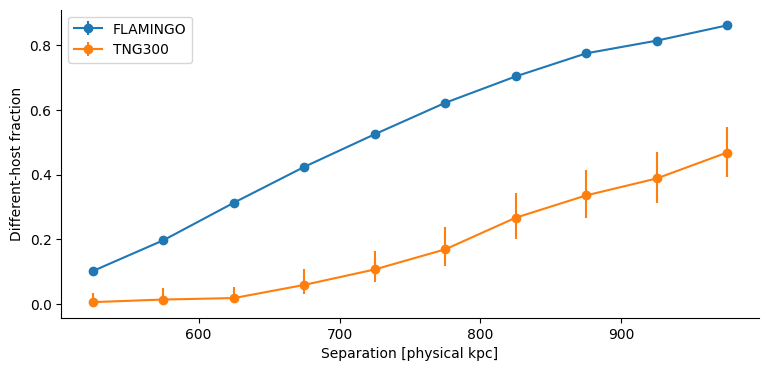

,lower_kpc,upper_kpc,flamingo_fraction,tng300_fraction,flamingo_pair_weight
0,500,550,0.089214,0.109150,1.223466
1,550,600,0.088794,0.093464,1.052599
2,600,650,0.089109,0.105882,1.188235
3,650,700,0.091807,0.099346,1.082127
4,700,750,0.095296,0.103922,1.090512
5,750,800,0.100040,0.092810,0.927734
6,800,850,0.103600,0.098039,0.946329
7,850,900,0.108883,0.099346,0.912415
8,900,950,0.113423,0.096078,0.847077
9,950,1000,0.119835,0.101961,0.850844


,bin_width_kpc,min_TNG_bin_count,flamingo_reweighted_different_fraction,gap_reduction_percentage_points,fraction_of_gap_accounted_for
0,25,60,0.528122,2.993498,0.079401
1,50,142,0.528711,2.934657,0.077840
2,100,301,0.530853,2.720454,0.072158


domain,flamingo,tng
feature,,
gr_diff,-0.214127,-0.304963
gr_mean,0.378421,0.407483
kappa_diff,0.026568,0.064112
kappa_mean,-0.260567,-0.469565
log_mass_ratio,-0.690605,-0.808451
log_stellar_sum,0.855442,0.868860
met_diff,0.027551,-0.008454
separation,0.102405,-0.011697
sigma_diff,0.590215,0.697367


In [5]:
host = table('populations/binned_host_fractions.csv')
fig, ax = plt.subplots()
for domain, part in host.groupby('simulation'):
    x=(part.lower_kpc+part.upper_kpc)/2
    ax.errorbar(x,part.different_host_fraction,
        yerr=np.vstack([part.different_host_fraction-part.wilson95_lower,
                         part.wilson95_upper-part.different_host_fraction]),fmt='o-',label=domain)
ax.set(xlabel='Separation [physical kpc]',ylabel='Different-host fraction');ax.legend();plt.show()
display(table('populations/separation_weights.csv'))
display(table('populations/bin_width_sensitivity.csv'))
corr=table('populations/eda_correlations.csv')
display(corr.query("subset == 'pooled'").pivot(index='feature',columns='domain',values='spearman'))

### Relating the EDA to the transfer results

A large marginal difference does not necessarily imply a large transfer error. Metallicity
differs strongly while chemistry transfers relatively well. Dispersion has closer marginals,
yet the morphology ablation identifies it as influential. Correlations summarize association;
the held-out and ablation experiments are needed to test prediction and transfer.

Further exploratory analysis is in [pair distributions](../research/notebooks/original/Pair_Distributions.ipynb),
[kinematic features](../research/notebooks/original/Kinematic-features_FLAMINGO.ipynb),
[feature analysis](../research/notebooks/original/feature_analysis.ipynb), and
[consistency checks](../research/notebooks/original/consistency_check.ipynb).
The [dispersion](../research/analogues/compute_sigma_star.py),
[corotation](../research/analogues/compute_kappa_corot.py), and
[metallicity](../research/analogues/compute_metallicity.py) scripts contain the particle-level definitions.


[Previous](01_catalogues_and_pair_selection.ipynb) · [Next](03_npe_and_experimental_design.ipynb) · [Repository map](../README.md)
